# GAD-7 Regression RL Model (Valence)
This model isolates the Valence framework (Model 2) and tests whether generalized anxiety symptoms (GAD-7) linearly predict the positive and negative learning rates.
Instead of allowing free individual variation, learning rates are strictly parameterized by GAD-7:
`alpha_pos(sub) = invlogit(intercept_pos + slope_pos * GAD7_normalized(sub))`
`alpha_neg(sub) = invlogit(intercept_neg + slope_neg * GAD7_normalized(sub))`

We extract the 89% Highest Density Interval (HDI) for the slopes to determine if the effect is credible.


In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"

import pandas as pd
import numpy as np
import pymc as pm
import pytensor
import pytensor.tensor as pt
import matplotlib.pyplot as plt
import arviz as az
import warnings

# Import custom hierarchical learning functions
from learning_functions import update_m2_hierarchical

warnings.filterwarnings('ignore')


In [2]:
# Load Data
file_path = '../data/allsubs_combined.csv'
df = pd.read_csv(file_path)

# Filter out trials with missing choices OR missing GAD7 scores
df = df.dropna(subset=['ChoiceKey', 'GAD7']).copy()

# Map stimulus IDs
stim_map = {'W1': 0, 'W2': 1, 'L1': 2, 'L2': 3}
df['LeftID_int'] = df['LeftID'].map(stim_map)
df['RightID_int'] = df['RightID'].map(stim_map)
df['ChosenID_int'] = df['ChosenID'].map(stim_map)

# Map ChoiceKey
df['Choice'] = df['ChoiceKey'] - 1

# Scale rewards
df['RewardScaled'] = df['TrialPoints'] / 30.0

# Create SubIdx (0 to n_sub-1)
unique_subs = df['Sub'].unique()
sub_idx_map = {sub: i for i, sub in enumerate(unique_subs)}
df['SubIdx'] = df['Sub'].map(sub_idx_map)
n_sub = len(unique_subs)

# Mark the first trial of each subject
df['is_first'] = 0
for sub in unique_subs:
    sub_indices = df[df['Sub'] == sub].index
    if len(sub_indices) > 0:
        df.loc[sub_indices[0], 'is_first'] = 1

# Extract and normalize GAD7 scores at the subject level
# Max possible score for GAD7 is 21 (7 questions * 3 points max)
# Normalizing to [0, 1] keeps sampling stable.
sub_gad7_map = df.groupby('SubIdx')['GAD7'].first()
gad7_scores = np.array([sub_gad7_map[i] for i in range(n_sub)])
gad7_normalized = gad7_scores / 21.0

print(f"Total subjects included: {n_sub} (Subjects with missing GAD7 removed)")
print(f"Total trials: {len(df)}")


Total subjects included: 67 (Subjects with missing GAD7 removed)
Total trials: 6520


In [3]:
def build_gad7_model(df, n_sub, gad7_normalized):
    with pm.Model() as m_gad7:
        # GAD7 array as a constant data variable
        gad7_data = pm.Data("gad7_data", gad7_normalized)
        
        # Positive Alpha Regression
        intercept_pos = pm.Normal('intercept_pos', mu=0, sigma=1.5)
        slope_pos = pm.Normal('slope_pos', mu=0, sigma=1.5)
        
        # Negative Alpha Regression
        intercept_neg = pm.Normal('intercept_neg', mu=0, sigma=1.5)
        slope_neg = pm.Normal('slope_neg', mu=0, sigma=1.5)
        
        # Compute deterministic alpha vectors
        alpha_pos = pm.Deterministic('alpha_pos', pm.math.invlogit(intercept_pos + slope_pos * gad7_data))
        alpha_neg = pm.Deterministic('alpha_neg', pm.math.invlogit(intercept_neg + slope_neg * gad7_data))
        
        # Hierarchical Beta (Inverse Temperature)
        mu_beta_log = pm.Normal('mu_beta_log', mu=0, sigma=2.0)
        sigma_beta = pm.HalfNormal('sigma_beta', sigma=1.0)
        beta_raw = pm.Normal('beta_raw', mu=0, sigma=1, shape=n_sub)
        beta = pm.Deterministic('beta', pm.math.exp(mu_beta_log + beta_raw * sigma_beta))
        
        Q_init = pt.zeros((n_sub, 4))
        outputs_info = [Q_init, None, None, None]
        
        results, updates = pytensor.scan(
            fn=update_m2_hierarchical,
            sequences=[
                pt.as_tensor_variable(df['LeftID_int'].values),
                pt.as_tensor_variable(df['RightID_int'].values),
                pt.as_tensor_variable(df['ChosenID_int'].values),
                pt.as_tensor_variable(df['RewardScaled'].values),
                pt.as_tensor_variable(df['is_first'].values),
                pt.as_tensor_variable(df['SubIdx'].values)
            ],
            outputs_info=outputs_info,
            non_sequences=[alpha_pos, alpha_neg],
            strict=True
        )
        
        q_left_seq = results[1]
        q_right_seq = results[2]
        
        sub_idx_seq = pt.as_tensor_variable(df['SubIdx'].values)
        p_right_raw = pm.math.sigmoid(beta[sub_idx_seq] * (q_right_seq - q_left_seq))
        p_right = pm.Deterministic('p_right', pt.clip(p_right_raw, 1e-5, 1.0 - 1e-5))
        
        pm.Bernoulli('choice_obs', p=p_right, observed=df['Choice'].values)
        
    return m_gad7

print("Building model...")
m_gad7 = build_gad7_model(df, n_sub, gad7_normalized)


Building model...


In [4]:
print("Sampling posterior using numpyro...")
with m_gad7:
    idata = pm.sample(nuts_sampler="numpyro", draws=1000, tune=1000, chains=4, progressbar=True)
print("Sampling complete!")


Sampling posterior using numpyro...


  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

Sampling complete!


GAD-7 REGRESSION RESULTS (89% HDI)
Slope Positive (alpha_pos) HDI 89%: [1.869, 4.448] -> EXCLUDES 0 (Credible effect at 89%)
Slope Negative (alpha_neg) HDI 89%: [-1.054, 0.261] -> INCLUDES 0 (Not strictly credible at 89%)



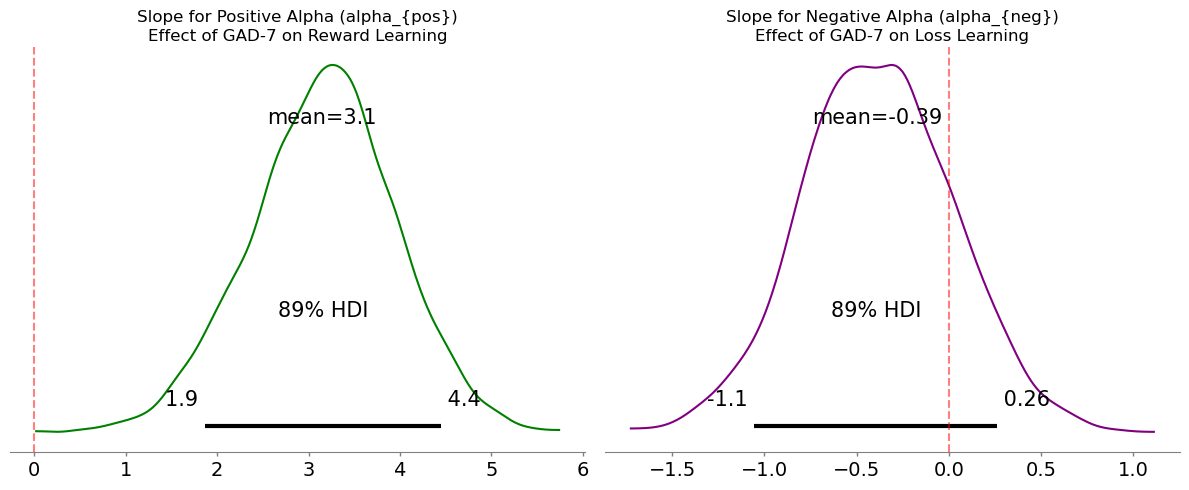

In [5]:
# Extract slopes
slope_pos_samples = idata.posterior['slope_pos'].values.flatten()
slope_neg_samples = idata.posterior['slope_neg'].values.flatten()

# Calculate 89% HDI
hdi_pos = az.hdi(slope_pos_samples, hdi_prob=0.89)
hdi_neg = az.hdi(slope_neg_samples, hdi_prob=0.89)

# Helper to check if 0 is included in HDI
def check_significance(hdi, slope_name):
    includes_zero = hdi[0] <= 0 <= hdi[1]
    status = "INCLUDES 0 (Not strictly credible at 89%)" if includes_zero else "EXCLUDES 0 (Credible effect at 89%)"
    print(f"{slope_name} HDI 89%: [{hdi[0]:.3f}, {hdi[1]:.3f}] -> {status}")

print("==================================================")
print("GAD-7 REGRESSION RESULTS (89% HDI)")
print("==================================================")
check_significance(hdi_pos, "Slope Positive (alpha_pos)")
check_significance(hdi_neg, "Slope Negative (alpha_neg)")
print("==================================================\n")

# Plot Posteriors
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

az.plot_posterior(idata.posterior, var_names=['slope_pos'], hdi_prob=0.89, ax=axes[0], color="green")
axes[0].set_title("Slope for Positive Alpha (alpha_{pos})\nEffect of GAD-7 on Reward Learning")
axes[0].axvline(0, color='red', linestyle='--', alpha=0.5)

az.plot_posterior(idata.posterior, var_names=['slope_neg'], hdi_prob=0.89, ax=axes[1], color="purple")
axes[1].set_title("Slope for Negative Alpha (alpha_{neg})\nEffect of GAD-7 on Loss Learning")
axes[1].axvline(0, color='red', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


CORRELATION BETWEEN ALPHA_POS AND ALPHA_NEG (NOTEBOOK 06 MODEL)
1. Subject-Level Posterior Means (N = 67, parameterized by GAD-7):
   Pearson r  = -0.9982 (p = 2.5080e-81)
   Spearman r = -1.0000 (p = 0.0000e+00)

2. Posterior Draw-Level Correlation (4,000 MCMC draws):
   Mean alpha_pos vs. Mean alpha_neg: Pearson r = -0.1982 (p = 9.9393e-37)
   slope_pos vs. slope_neg:           Pearson r = -0.1773 (p = 1.2958e-29)



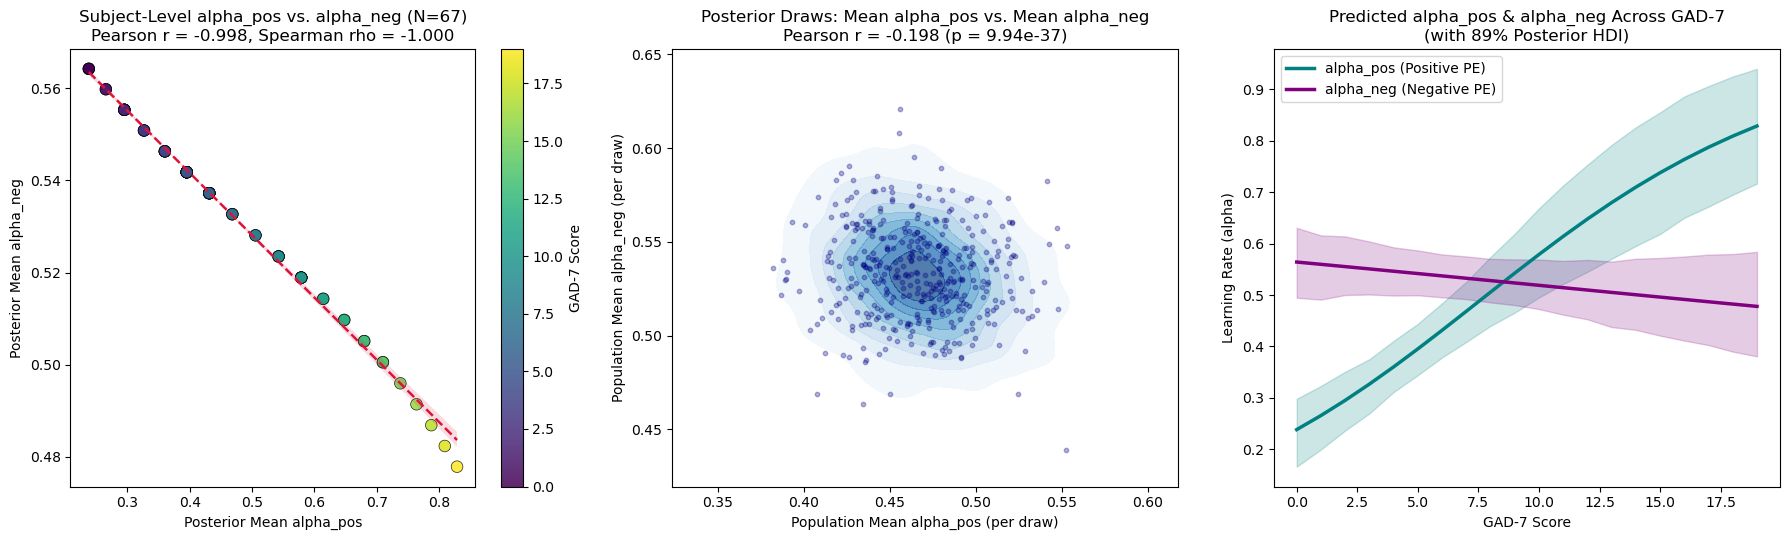

In [6]:
import seaborn as sns
from scipy import stats

# Extract subject-level posterior means and 89% HDIs for alpha_pos and alpha_neg
alpha_pos_samples = idata.posterior['alpha_pos'].values.reshape(-1, n_sub)  # (n_draws, n_sub)
alpha_neg_samples = idata.posterior['alpha_neg'].values.reshape(-1, n_sub)  # (n_draws, n_sub)

alpha_pos_mean = alpha_pos_samples.mean(axis=0)
alpha_neg_mean = alpha_neg_samples.mean(axis=0)

# Draw-level mean learning rates across subjects (4000 posterior draws)
draw_mean_pos = alpha_pos_samples.mean(axis=1)
draw_mean_neg = alpha_neg_samples.mean(axis=1)

# Correlations
r_sub, p_sub = stats.pearsonr(alpha_pos_mean, alpha_neg_mean)
rho_sub, prho_sub = stats.spearmanr(alpha_pos_mean, alpha_neg_mean)

r_draw, p_draw = stats.pearsonr(draw_mean_pos, draw_mean_neg)
slope_pos_draws = idata.posterior['slope_pos'].values.flatten()
slope_neg_draws = idata.posterior['slope_neg'].values.flatten()
r_slope, p_slope = stats.pearsonr(slope_pos_draws, slope_neg_draws)

print("==================================================================")
print("CORRELATION BETWEEN ALPHA_POS AND ALPHA_NEG (NOTEBOOK 06 MODEL)")
print("==================================================================")
print(f"1. Subject-Level Posterior Means (N = {n_sub}, parameterized by GAD-7):")
print(f"   Pearson r  = {r_sub:.4f} (p = {p_sub:.4e})")
print(f"   Spearman r = {rho_sub:.4f} (p = {prho_sub:.4e})")
print(f"\n2. Posterior Draw-Level Correlation (4,000 MCMC draws):")
print(f"   Mean alpha_pos vs. Mean alpha_neg: Pearson r = {r_draw:.4f} (p = {p_draw:.4e})")
print(f"   slope_pos vs. slope_neg:           Pearson r = {r_slope:.4f} (p = {p_slope:.4e})")
print("==================================================================\n")

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Panel 1: Subject-level alpha_pos vs alpha_neg colored by GAD-7
sc = axes[0].scatter(alpha_pos_mean, alpha_neg_mean, c=gad7_scores, cmap='viridis', s=70, alpha=0.85, edgecolors='k', linewidth=0.5)
sns.regplot(x=alpha_pos_mean, y=alpha_neg_mean, ax=axes[0], scatter=False, color='crimson', line_kws={'linestyle': '--', 'linewidth': 1.8})
cbar = plt.colorbar(sc, ax=axes[0])
cbar.set_label('GAD-7 Score')
axes[0].set_title(f"Subject-Level alpha_pos vs. alpha_neg (N={n_sub})\nPearson r = {r_sub:.3f}, Spearman rho = {rho_sub:.3f}")
axes[0].set_xlabel("Posterior Mean alpha_pos")
axes[0].set_ylabel("Posterior Mean alpha_neg")

# Panel 2: Posterior Draw-Level Mean alpha_pos vs Mean alpha_neg
sns.kdeplot(x=draw_mean_pos, y=draw_mean_neg, ax=axes[1], cmap="Blues", fill=True, thresh=0.05, alpha=0.7)
axes[1].scatter(draw_mean_pos[::10], draw_mean_neg[::10], color='navy', s=10, alpha=0.3)
axes[1].set_title(f"Posterior Draws: Mean alpha_pos vs. Mean alpha_neg\nPearson r = {r_draw:.3f} (p = {p_draw:.2e})")
axes[1].set_xlabel("Population Mean alpha_pos (per draw)")
axes[1].set_ylabel("Population Mean alpha_neg (per draw)")

# Panel 3: Both learning rates as a function of GAD-7 with 89% HDI
sort_idx = np.argsort(gad7_scores)
g_sorted = gad7_scores[sort_idx]
pos_hdi = az.hdi(alpha_pos_samples[:, sort_idx], hdi_prob=0.89)
neg_hdi = az.hdi(alpha_neg_samples[:, sort_idx], hdi_prob=0.89)

axes[2].plot(g_sorted, alpha_pos_mean[sort_idx], color='teal', lw=2.5, label='alpha_pos (Positive PE)')
axes[2].fill_between(g_sorted, pos_hdi[:, 0], pos_hdi[:, 1], color='teal', alpha=0.2)
axes[2].plot(g_sorted, alpha_neg_mean[sort_idx], color='purple', lw=2.5, label='alpha_neg (Negative PE)')
axes[2].fill_between(g_sorted, neg_hdi[:, 0], neg_hdi[:, 1], color='purple', alpha=0.2)
axes[2].set_title("Predicted alpha_pos & alpha_neg Across GAD-7\n(with 89% Posterior HDI)")
axes[2].set_xlabel("GAD-7 Score")
axes[2].set_ylabel("Learning Rate (alpha)")
axes[2].legend(loc='best')

plt.tight_layout()
plt.savefig('../data/alpha_pos_vs_alpha_neg_nb06.png', dpi=150, bbox_inches='tight')
plt.show()
